# 02. Add Complex Gaussian Noise

### 목적

공개 QSM 데이터에서 복원한 5-echo complex GRE 영상에 synthetic complex Gaussian noise를 추가한다.

생성할 잡음 조건은 다음과 같다.

- 10%
- 30%
- 50%
- Random seed: 42

이번 실험에서는 MRI의 complex noise model을 반영하여 Real 성분과 Imaginary 성분에 서로 독립적인 zero-mean Gaussian noise를 추가한다.

잡음은 brain mask 내부에만 제한하지 않고 전체 3D 영상에 추가한다. Brain mask는 잡음 표준편차 계산과 이후 평가 범위 설정에 사용한다.

원본 complex 데이터는 변경하지 않고, 잡음이 추가된 데이터를 별도 NPZ 파일로 저장한다.

In [5]:
import gc
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

## 1. 실험 설정

입력 파일은 `01_Load_data.ipynb`에서 생성한 전처리 결과를 사용한다.

입력 NPZ 파일에는 다음 변수가 저장되어 있다.

- `meas_gre`: 4D complex GRE
- `brain_mask`: 잡음 크기 계산 및 영상 평가용 mask
- `qsm_mask`: 최종 QSM 평가용 mask
- `echo_times`: EchoTime, 단위 second
- `field_strength`: 자기장 세기, 단위 Tesla
- `affine`: NIfTI 공간정보

10%, 30%, 50% 조건에서 동일한 random seed를 다시 사용한다. 따라서 세 조건은 동일한 잡음 패턴을 사용하고 잡음의 크기만 달라진다.

In [6]:
# ------------------------------------------------------------
# 프로젝트 경로 자동 확인
# ------------------------------------------------------------
current_dir = Path.cwd().resolve()

project_candidates = [
    current_dir,
    current_dir.parent,
    current_dir / "01_public_qsm",
]

PROJECT_ROOT = None

for candidate in project_candidates:
    expected_input = (
        candidate
        / "data"
        / "processed"
        / "qsm_consensus_siemens_monopolar_complex.npz"
    )

    if expected_input.exists():
        PROJECT_ROOT = candidate
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "01_public_qsm 프로젝트 폴더를 찾을 수 없습니다.\n"
        "이 노트북을 01_public_qsm/notebooks 폴더에 저장한 뒤 다시 실행하세요."
    )


# ------------------------------------------------------------
# 입력 및 출력 경로
# ------------------------------------------------------------
PROCESSED_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "qsm_consensus_siemens_monopolar_complex.npz"
)

OUT_DIR = PROJECT_ROOT / "data" / "noisy"
OUT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 실험 조건
# ------------------------------------------------------------
NOISE_LEVELS = [0.1, 0.3, 0.5]
SEED = 42

print("Project root :", PROJECT_ROOT)
print("Input file   :", PROCESSED_PATH)
print("Output folder:", OUT_DIR)
print("Noise levels :", NOISE_LEVELS)
print("Random seed  :", SEED)

Project root : C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm
Input file   : C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\processed\qsm_consensus_siemens_monopolar_complex.npz
Output folder: C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy
Noise levels : [0.1, 0.3, 0.5]
Random seed  : 42


## 2. 전처리된 Complex GRE 불러오기

입력 데이터가 다음 조건을 만족하는지 확인한다.

1. `meas_gre`가 4차원 complex array인가?
2. 마지막 축이 echo 축인가?
3. Brain mask와 QSM mask의 공간 shape이 영상과 같은가?
4. QSM mask가 brain mask 내부에 포함되는가?
5. 영상에 NaN 또는 Inf가 없는가?
6. EchoTime 개수가 echo 개수와 같은가?

In [7]:
if not PROCESSED_PATH.exists():
    raise FileNotFoundError(f"입력 파일이 없습니다:\n{PROCESSED_PATH}")

with np.load(PROCESSED_PATH, allow_pickle=False) as data:
    print("입력 파일 변수:", data.files)

    required_keys = {
        "meas_gre",
        "brain_mask",
        "qsm_mask",
        "echo_times",
        "field_strength",
        "affine",
    }

    missing_keys = required_keys - set(data.files)

    if missing_keys:
        raise KeyError(f"입력 NPZ에 필요한 변수가 없습니다: {missing_keys}")

    meas_gre = data["meas_gre"].astype(np.complex64, copy=True)
    brain_mask = data["brain_mask"].astype(bool, copy=True)
    qsm_mask = data["qsm_mask"].astype(bool, copy=True)

    echo_times = data["echo_times"].astype(np.float64, copy=True)
    field_strength = float(data["field_strength"])
    affine = data["affine"].astype(np.float64, copy=True)


# ------------------------------------------------------------
# 입력 검증
# ------------------------------------------------------------
if meas_gre.ndim != 4:
    raise ValueError(f"meas_gre는 4D여야 합니다. 현재 shape={meas_gre.shape}")

if not np.iscomplexobj(meas_gre):
    raise TypeError("meas_gre가 complex array가 아닙니다.")

spatial_shape = meas_gre.shape[:3]
n_echoes = meas_gre.shape[-1]

if brain_mask.shape != spatial_shape:
    raise ValueError(
        f"Brain mask shape 불일치: "
        f"{brain_mask.shape} vs {spatial_shape}"
    )

if qsm_mask.shape != spatial_shape:
    raise ValueError(
        f"QSM mask shape 불일치: "
        f"{qsm_mask.shape} vs {spatial_shape}"
    )

if not np.any(brain_mask):
    raise ValueError("Brain mask가 비어 있습니다.")

if np.any(qsm_mask & ~brain_mask):
    raise ValueError("QSM mask 일부가 brain mask 밖에 있습니다.")

if echo_times.shape != (n_echoes,):
    raise ValueError(
        f"EchoTime shape 불일치: "
        f"{echo_times.shape} vs ({n_echoes},)"
    )

if not (
    np.isfinite(meas_gre.real).all()
    and np.isfinite(meas_gre.imag).all()
):
    raise ValueError("meas_gre에 NaN 또는 Inf가 있습니다.")

if not np.isfinite(echo_times).all():
    raise ValueError("EchoTime에 NaN 또는 Inf가 있습니다.")

if affine.shape != (4, 4):
    raise ValueError(f"Affine shape이 올바르지 않습니다: {affine.shape}")


# ------------------------------------------------------------
# 데이터 정보 출력
# ------------------------------------------------------------
print()
print("===== Input data summary =====")
print("Complex shape       :", meas_gre.shape)
print("Complex dtype       :", meas_gre.dtype)
print("Number of echoes    :", n_echoes)
print("Brain mask voxels   :", int(brain_mask.sum()))
print("QSM mask voxels     :", int(qsm_mask.sum()))
print("Echo times [ms]     :", echo_times * 1000)
print("Field strength [T]  :", field_strength)
print("Affine shape        :", affine.shape)

입력 파일 변수: ['meas_gre', 'brain_mask', 'qsm_mask', 'echo_times', 'field_strength', 'affine']

===== Input data summary =====
Complex shape       : (176, 256, 144, 5)
Complex dtype       : complex64
Number of echoes    : 5
Brain mask voxels   : 1780588
QSM mask voxels     : 1591599
Echo times [ms]     : [ 5.25 11.08 16.91 22.74 28.57]
Field strength [T]  : 3.0
Affine shape        : (4, 4)


## 3. 잡음 크기 계산

Brain mask 내부에서 각 echo의 평균 magnitude를 계산한다.

Echo $e$의 평균 magnitude는 다음과 같이 정의한다.

$$
\bar{M}_e
=
\frac{1}{|B|}
\sum_{v \in B}
|S_e(v)|
$$

여기서 $B$는 brain mask이며, $S_e(v)$는 echo $e$에서 voxel $v$의 complex signal이다.

전체 기준 magnitude는 5개 echo 평균의 평균으로 정의한다.

$$
\bar{M}
=
\frac{1}{E}
\sum_{e=1}^{E}
\bar{M}_e
$$

Noise level을 $r$이라고 할 때 Real 및 Imaginary 성분에 적용되는 Gaussian noise의 표준편차는 다음과 같다.

$$
\sigma_r = r\bar{M}
$$

따라서 10%, 30%, 50% 조건에서는 각각 다음 값을 사용한다.

$$
r \in \{0.1, 0.3, 0.5\}
$$

In [8]:
mean_magnitude_by_echo = []

print("===== Mean magnitude inside brain mask =====")

for echo_idx in range(n_echoes):
    magnitude_echo = np.abs(meas_gre[..., echo_idx])
    mean_value = float(magnitude_echo[brain_mask].mean())
    mean_magnitude_by_echo.append(mean_value)

    print(
        f"Echo {echo_idx + 1}: "
        f"{mean_value:.6f}"
    )

overall_mean = float(np.mean(mean_magnitude_by_echo))

if not np.isfinite(overall_mean):
    raise ValueError("기준 magnitude가 유효한 값이 아닙니다.")

if overall_mean <= 0:
    raise ValueError(f"기준 magnitude가 0 이하입니다: {overall_mean}")

print()
print(
    "Overall mean magnitude:",
    f"{overall_mean:.6f}",
)

print()
print("===== Target noise sigma =====")

for noise_ratio in NOISE_LEVELS:
    noise_percent = int(round(noise_ratio * 100))
    sigma = overall_mean * noise_ratio

    print(
        f"{noise_percent:>2}%: "
        f"sigma/component = {sigma:.6f}" 
    )

===== Mean magnitude inside brain mask =====
Echo 1: 358.104736
Echo 2: 318.326782
Echo 3: 284.136292
Echo 4: 254.343109
Echo 5: 227.990555

Overall mean magnitude: 288.580295

===== Target noise sigma =====
10%: sigma/component = 28.858029
30%: sigma/component = 86.574088
50%: sigma/component = 144.290147


## 4. Complex Gaussian noise 생성

원본 complex signal을 다음과 같이 나타낸다.

$$
S = S_{\mathrm{real}} + iS_{\mathrm{imag}}
$$

Real noise와 Imaginary noise는 서로 독립적인 Gaussian distribution에서 생성한다.

$$
n_{\mathrm{real}}
\sim
\mathcal{N}(0,\sigma^2)
$$

$$
n_{\mathrm{imag}}
\sim
\mathcal{N}(0,\sigma^2)
$$

잡음이 추가된 complex signal은 다음과 같다.

$$
S_{\mathrm{noisy}}
=
S
+
n_{\mathrm{real}}
+
in_{\mathrm{imag}}
$$

잡음은 brain mask 내부에만 제한하지 않고 전체 영상에 추가한다.

모든 noise level에서 random generator를 동일한 seed로 다시 초기화한다. 따라서 10%, 30%, 50% 조건은 동일한 표준정규 잡음 패턴을 공유하며, 표준편차만 다르게 scaling된다.

각 noise level은 별도 NPZ 파일로 즉시 저장한다. 여러 개의 4D complex 영상을 메모리에 동시에 보관하지 않는다.

In [9]:
generated_files = {}

for noise_ratio in NOISE_LEVELS:
    noise_percent = int(round(noise_ratio * 100))
    sigma = float(overall_mean * noise_ratio)

    print()
    print("=" * 60)
    print(f"Noise level     : {noise_percent}%")
    print(f"Sigma/component : {sigma:.6f}")
    print(f"Random seed     : {SEED}")
    print("Noise scope     : whole volume")
    print("=" * 60)

    # Noise level마다 같은 seed로 재시작한다.
    # 따라서 10%, 30%, 50%는 같은 noise pattern을 공유한다.
    rng = np.random.default_rng(SEED)

    noisy_complex = np.empty_like(
        meas_gre,
        dtype=np.complex64,
    )

    # Brain mask 내부에서 실제 생성된 noise의 통계를 계산하기 위한 값
    real_sum = 0.0
    real_square_sum = 0.0

    imag_sum = 0.0
    imag_square_sum = 0.0

    statistics_count = 0

    for echo_idx in range(n_echoes):
        orig_echo = meas_gre[..., echo_idx]

        # float32로 직접 생성하여 메모리 사용량을 줄인다.
        noise_real = rng.standard_normal(
            size=orig_echo.shape,
            dtype=np.float32,
        )
        noise_real *= np.float32(sigma)

        noise_imag = rng.standard_normal(
            size=orig_echo.shape,
            dtype=np.float32,
        )
        noise_imag *= np.float32(sigma)

        noise_complex = (
            noise_real + 1j * noise_imag
        ).astype(
            np.complex64,
            copy=False,
        )

        # Brain mask로 제한하지 않고 전체 영상에 잡음 추가
        noisy_complex[..., echo_idx] = (
            orig_echo + noise_complex
        ).astype(
            np.complex64,
            copy=False,
        )

        # 평가 영역인 brain mask 내부 noise 통계
        real_inside = noise_real[brain_mask]
        imag_inside = noise_imag[brain_mask]

        real_sum += float(
            np.sum(real_inside, dtype=np.float64)
        )
        real_square_sum += float(
            np.sum(real_inside * real_inside, dtype=np.float64)
        )

        imag_sum += float(
            np.sum(imag_inside, dtype=np.float64)
        )
        imag_square_sum += float(
            np.sum(imag_inside * imag_inside, dtype=np.float64)
        )

        statistics_count += real_inside.size

        del noise_real
        del noise_imag
        del noise_complex
        del real_inside
        del imag_inside

    # --------------------------------------------------------
    # 생성된 noise의 평균과 표준편차 계산
    # --------------------------------------------------------
    measured_mean_real = real_sum / statistics_count
    measured_mean_imag = imag_sum / statistics_count

    measured_var_real = (
        real_square_sum / statistics_count
        - measured_mean_real ** 2
    )

    measured_var_imag = (
        imag_square_sum / statistics_count
        - measured_mean_imag ** 2
    )

    measured_std_real = float(np.sqrt(max(measured_var_real, 0.0)))
    measured_std_imag = float(np.sqrt(max(measured_var_imag, 0.0)))

    # --------------------------------------------------------
    # 결과 저장
    # --------------------------------------------------------
    output_path = OUT_DIR / (
        "qsm_siemens_monopolar_"
        f"noise{noise_percent:02d}_"
        f"seed{SEED}.npz"
    )

    np.savez_compressed(
        output_path,

        # 영상
        noisy_complex=noisy_complex,

        # Masks
        brain_mask=brain_mask,
        qsm_mask=qsm_mask,

        # 촬영 및 공간정보
        echo_times=echo_times,
        field_strength=np.float32(field_strength),
        affine=affine,

        # Noise 조건
        noise_ratio=np.float32(noise_ratio),
        noise_level_percent=np.int16(noise_percent),
        sigma=np.float32(sigma),
        seed=np.int64(SEED),

        # Sigma 계산 정보
        reference_mean_magnitude=np.float32(overall_mean),
        mean_magnitude_by_echo=np.asarray(
            mean_magnitude_by_echo,
            dtype=np.float32,
        ),

        # 실험 정의
        noise_scope=np.asarray("whole_volume"),
        sigma_definition=np.asarray("std_per_real_and_imag_component"),

        # 생성된 noise 확인값
        measured_mean_real=np.float32(measured_mean_real),
        measured_std_real=np.float32(measured_std_real),
        measured_mean_imag=np.float32(measured_mean_imag),
        measured_std_imag=np.float32(measured_std_imag),
    )

    generated_files[noise_percent] = output_path

    file_size_mb = output_path.stat().st_size / (1024 ** 2)

    print()
    print("저장 완료:", output_path)
    print(f"파일 크기: {file_size_mb:.2f} MB")

    print()
    print("===== Generated noise check =====")
    print(
        "Target sigma       :",
        f"{sigma:.6f}",
    )
    print(
        "Real mean/std      :",
        f"{measured_mean_real:.6f}",
        f"/ {measured_std_real:.6f}",
    )
    print(
        "Imaginary mean/std :",
        f"{measured_mean_imag:.6f}",
        f"/ {measured_std_imag:.6f}",
    )

    # 다음 noise level을 생성하기 전에 메모리 해제
    del noisy_complex
    gc.collect()

print()
print("모든 noise level 생성 완료")


Noise level     : 10%
Sigma/component : 28.858029
Random seed     : 42
Noise scope     : whole volume

저장 완료: C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise10_seed42.npz
파일 크기: 230.76 MB

===== Generated noise check =====
Target sigma       : 28.858029
Real mean/std      : -0.009808 / 28.869321
Imaginary mean/std : -0.005721 / 28.857950

Noise level     : 30%
Sigma/component : 86.574088
Random seed     : 42
Noise scope     : whole volume

저장 완료: C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise30_seed42.npz
파일 크기: 229.94 MB

===== Generated noise check =====
Target sigma       : 86.574088
Real mean/std      : -0.029423 / 86.607963
Imaginary mean/std : -0.017164 / 86.573847

Noise level     : 50%
Sigma/component : 144.290147
Random seed     : 42
Noise scope     : whole volume

저장 완료: C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise

## 5. 저장 파일 검증

저장한 NPZ 파일을 다시 불러와 다음 항목을 확인한다.

- 저장 파일이 실제로 존재하는가?
- 모든 필수 변수가 포함되어 있는가?
- `noisy_complex`의 shape과 dtype이 올바른가?
- Brain mask와 QSM mask가 원본과 같은가?
- NaN 또는 Inf가 없는가?
- Noise level, sigma, seed가 올바르게 저장되었는가?

In [10]:
required_output_keys = {
    "noisy_complex",
    "brain_mask",
    "qsm_mask",
    "echo_times",
    "field_strength",
    "affine",
    "noise_ratio",
    "noise_level_percent",
    "sigma",
    "seed",
    "reference_mean_magnitude",
    "mean_magnitude_by_echo",
    "noise_scope",
    "sigma_definition",
    "measured_mean_real",
    "measured_std_real",
    "measured_mean_imag",
    "measured_std_imag",
}

print("===== Saved file validation =====")

for noise_percent, output_path in generated_files.items():
    if not output_path.exists():
        raise FileNotFoundError(f"저장 파일을 찾을 수 없습니다:\n{output_path}")

    with np.load(output_path, allow_pickle=False) as saved:
        missing_keys = required_output_keys - set(saved.files)

        if missing_keys:
            raise KeyError(
                f"{noise_percent}% 파일에서 "
                f"변수가 누락되었습니다: {missing_keys}"
            )

        saved_noisy = saved["noisy_complex"]
        saved_brain_mask = saved["brain_mask"]
        saved_qsm_mask = saved["qsm_mask"]

        if saved_noisy.shape != meas_gre.shape:
            raise ValueError(
                f"{noise_percent}% shape 불일치: "
                f"{saved_noisy.shape}"
            )

        if saved_noisy.dtype != np.complex64:
            raise TypeError(
                f"{noise_percent}% dtype 불일치: "
                f"{saved_noisy.dtype}"
            )

        if not (
            np.isfinite(saved_noisy.real).all()
            and np.isfinite(saved_noisy.imag).all()
        ):
            raise ValueError(f"{noise_percent}% 영상에 NaN 또는 Inf가 있습니다.")

        if not np.array_equal(saved_brain_mask, brain_mask):
            raise ValueError(f"{noise_percent}% Brain mask가 원본과 다릅니다.")

        if not np.array_equal(saved_qsm_mask, qsm_mask):
            raise ValueError(f"{noise_percent}% QSM mask가 원본과 다릅니다.")

        saved_level = int(saved["noise_level_percent"])

        saved_seed = int(saved["seed"])
        saved_sigma = float(saved["sigma"])
        saved_scope = str(saved["noise_scope"])

        if saved_level != noise_percent:
            raise ValueError(f"Noise level 저장값 오류: {saved_level}")

        if saved_seed != SEED:
            raise ValueError(f"Seed 저장값 오류: {saved_seed}")

        if saved_scope != "whole_volume":
            raise ValueError(f"Noise scope 저장값 오류: {saved_scope}")

        print()
        print(f"{noise_percent}% 검증 통과")
        print(" Path :", output_path)
        print(" Shape:", saved_noisy.shape)
        print(" Dtype:", saved_noisy.dtype)
        print(" Sigma:", saved_sigma)
        print(" Seed :", saved_seed)
        print(" Scope:", saved_scope)

print()
print("모든 저장 파일 검증 통과")

===== Saved file validation =====

10% 검증 통과
 Path : C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise10_seed42.npz
 Shape: (176, 256, 144, 5)
 Dtype: complex64
 Sigma: 28.858030319213867
 Seed : 42
 Scope: whole_volume

30% 검증 통과
 Path : C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise30_seed42.npz
 Shape: (176, 256, 144, 5)
 Dtype: complex64
 Sigma: 86.57408905029297
 Seed : 42
 Scope: whole_volume

50% 검증 통과
 Path : C:\Users\lilly\OneDrive - 한국외국어대학교\바탕 화면\졸업프로젝트\01_public_qsm\data\noisy\qsm_siemens_monopolar_noise50_seed42.npz
 Shape: (176, 256, 144, 5)
 Dtype: complex64
 Sigma: 144.29014587402344
 Seed : 42
 Scope: whole_volume

모든 저장 파일 검증 통과


## 6. Original 및 Noisy 영상 비교

Echo 1의 중앙 slice에서 다음 영상을 비교한다.

1. Original magnitude
2. Noisy magnitude
3. Magnitude difference
4. 추가된 complex noise의 Real 성분

Magnitude difference는 complex noise 자체와 동일하지 않다. Complex Gaussian noise를 추가한 뒤 magnitude를 계산하면 비선형 변환에 의해 magnitude bias가 발생할 수 있다.

따라서 잡음의 평균과 표준편차 검증에는 다음 complex difference를 사용한다.

$$
N
=
S_{\mathrm{noisy}}
-
S_{\mathrm{original}}
$$

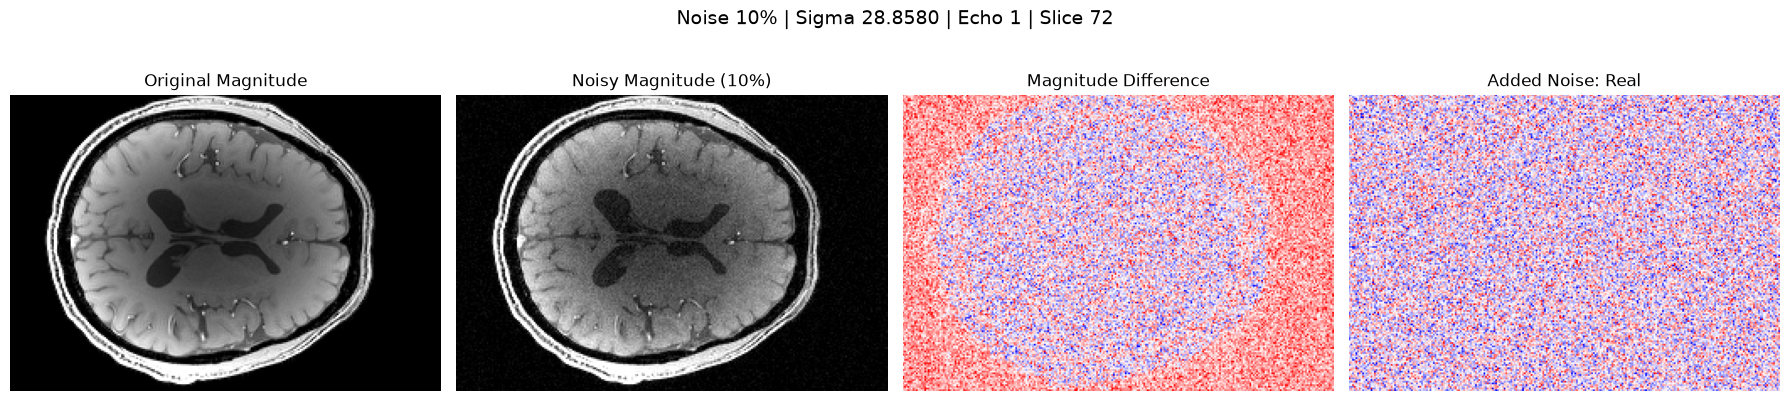

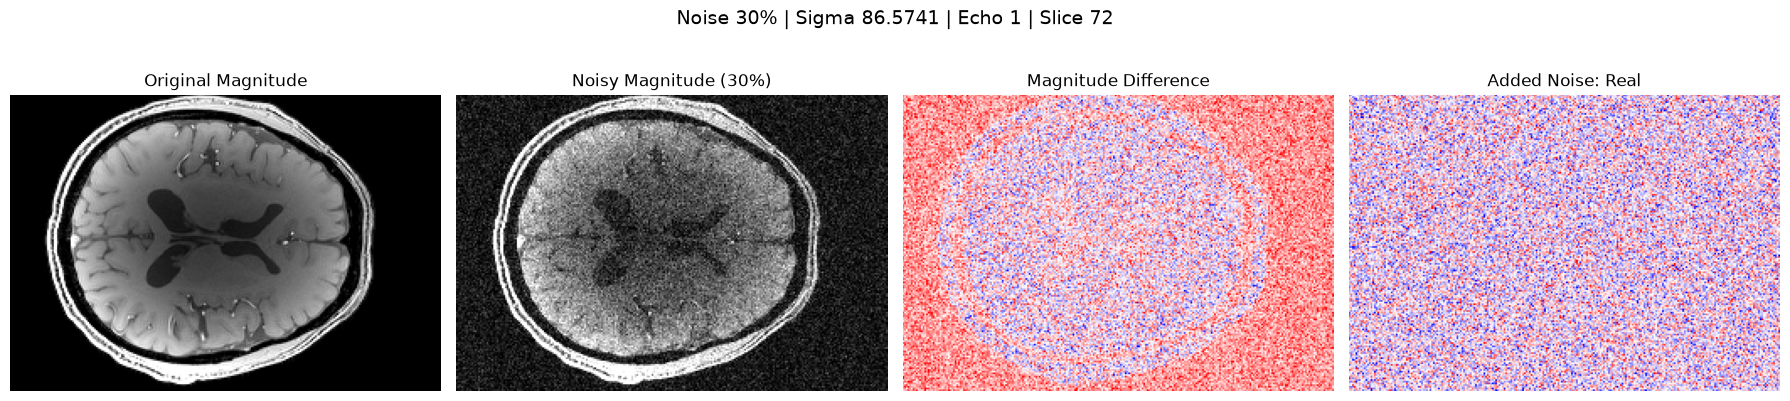

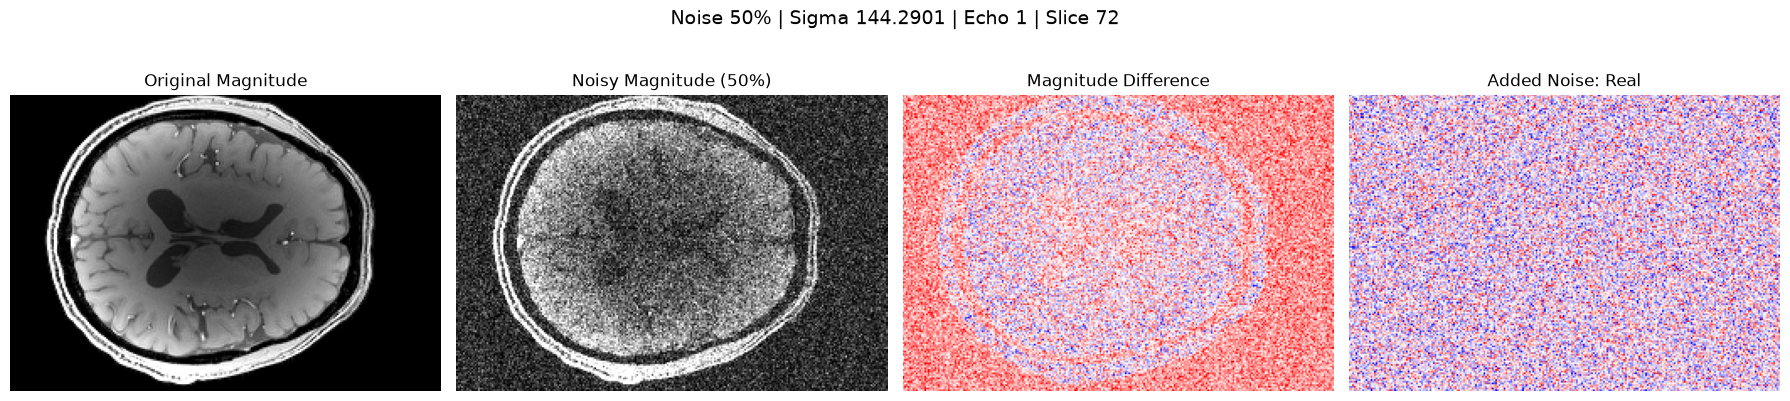

In [11]:
echo_idx = 0
slice_idx = meas_gre.shape[2] // 2

original_echo = meas_gre[..., echo_idx]
original_magnitude = np.abs(original_echo)

original_slice = original_magnitude[:, :, slice_idx]

brain_values = original_magnitude[brain_mask]

vmin, vmax = np.percentile(brain_values, [1, 99])

for noise_percent in [10, 30, 50]:
    output_path = generated_files[noise_percent]

    with np.load(output_path, allow_pickle=False) as saved:
        noisy_echo = saved["noisy_complex"][..., echo_idx]
        sigma = float(saved["sigma"])

    noisy_magnitude = np.abs(noisy_echo)
    noisy_slice = noisy_magnitude[:, :, slice_idx]

    magnitude_difference = noisy_slice - original_slice

    complex_noise_slice = noisy_echo[:, :, slice_idx] - original_echo[:, :, slice_idx]
    real_noise_slice = complex_noise_slice.real

    diff_limit = float(np.percentile(np.abs(magnitude_difference), 99))
    noise_limit = float(np.percentile(np.abs(real_noise_slice), 99))

    diff_limit = max(diff_limit, 1e-8)
    noise_limit = max(noise_limit, 1e-8)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

    axes[0].imshow(original_slice, cmap="gray", vmin=vmin, vmax=vmax)
    axes[0].set_title("Original Magnitude")

    axes[1].imshow(noisy_slice, cmap="gray", vmin=vmin, vmax=vmax)
    axes[1].set_title(f"Noisy Magnitude ({noise_percent}%)")

    axes[2].imshow(magnitude_difference, cmap="bwr", vmin=-diff_limit, vmax=diff_limit)
    axes[2].set_title("Magnitude Difference")

    axes[3].imshow(real_noise_slice, cmap="bwr", vmin=-noise_limit, vmax=noise_limit)
    axes[3].set_title("Added Noise: Real")

    for axis in axes:
        axis.axis("off")

    fig.suptitle(
        f"Noise {noise_percent}% | "
        f"Sigma {sigma:.4f} | "
        f"Echo {echo_idx + 1} | "
        f"Slice {slice_idx}",
        fontsize=14,
    )

    plt.tight_layout()
    plt.show()

    del noisy_echo
    del noisy_magnitude
    del complex_noise_slice
    gc.collect()

## 7. 생성 결과 요약

이번 단계에서 생성한 데이터는 다음과 같다.

- Original pseudo-reference: 5-echo complex GRE
- Noise levels: 10%, 30%, 50%
- Seed: 42
- Noise distribution: independent zero-mean Gaussian noise
- Noise components: Real 및 Imaginary
- Noise scope: 전체 영상
- Sigma reference: Brain mask 내부 전체 echo 평균 magnitude

10%, 30%, 50%는 magnitude 영상의 표준편차가 아니라 Real 및 Imaginary 각 성분에 적용된 Gaussian noise 표준편차의 비율을 의미한다.

원본 공개 데이터는 완전히 잡음이 없는 ground truth가 아니므로, 본 실험에서는 원본 영상을 pseudo-reference로 사용한다.

In [12]:
print("===== Noise generation summary =====")
print("Original shape       :", meas_gre.shape)
print("Original dtype       :", meas_gre.dtype)
print("Number of echoes     :", n_echoes)
print("Brain mask voxels    :", int(brain_mask.sum()))
print("QSM mask voxels      :", int(qsm_mask.sum()))
print("Reference magnitude  :", overall_mean)
print("Random seed          :", SEED)
print("Noise scope          : whole volume")
print()

for noise_percent in [10, 30, 50]:
    output_path = generated_files[noise_percent]

    with np.load(output_path, allow_pickle=False) as saved:
        print(
            f"{noise_percent:>2}% | "
            f"sigma/component="
            f"{float(saved['sigma']):.6f} | "
            f"Real std="
            f"{float(saved['measured_std_real']):.6f} | "
            f"Imag std="
            f"{float(saved['measured_std_imag']):.6f}"
        )

        print("    ", output_path.name)

===== Noise generation summary =====
Original shape       : (176, 256, 144, 5)
Original dtype       : complex64
Number of echoes     : 5
Brain mask voxels    : 1780588
QSM mask voxels      : 1591599
Reference magnitude  : 288.5802947998047
Random seed          : 42
Noise scope          : whole volume

10% | sigma/component=28.858030 | Real std=28.869322 | Imag std=28.857950
     qsm_siemens_monopolar_noise10_seed42.npz
30% | sigma/component=86.574089 | Real std=86.607964 | Imag std=86.573845
     qsm_siemens_monopolar_noise30_seed42.npz
50% | sigma/component=144.290146 | Real std=144.346603 | Imag std=144.289749
     qsm_siemens_monopolar_noise50_seed42.npz
